# Early-Warning Classifier for Students at Risk of Failing Maths
**Course:** Programming for Artificial Intelligence | **Semester:** Fall 2026 | **CUSIT**
**Domain:** Education | **Task:** Binary classification (scikit-learn)

**Team:** *(write your team members' names and roll numbers here)*

**How to run:** Open in Google Colab or Jupyter and click *Run all*. The data is read straight from a GitHub link. Needs: `pandas numpy matplotlib scikit-learn`.

## 1. Problem Definition (Milestone 1)

**Stakeholder:** A secondary school maths teacher / academic coordinator.

**Problem:** Teachers usually find out a student is failing only when the final result arrives, which is too late to help. We want a tool that flags students who are **likely to fail** early, so the school can offer support (tutoring, talking to parents, etc.).

**Intended use:** A *support* tool that makes a list of students for the teacher to look at more closely after the first term. It is **not** used to punish, rank, grade or make final decisions about any student.

| Item | Our definition |
|---|---|
| Target | `at_risk` = 1 if final maths grade `G3` is below 10 (out of 20), else 0 |
| Features | Background, family, study habits, lifestyle, past failures, absences, and first-period grade `G1` |
| Positive class | "at risk" (the one we want to catch) |

**Success criteria**
1. **Recall for at-risk ≥ 0.80** on unseen test data (catch at least 8 of 10 students who will really fail).
2. **Precision for at-risk ≥ 0.65** (so teachers are not flooded with false alarms).

**Main metric: Recall.** Missing a student who needs help costs more than checking a student who turns out fine. We also track F1 because precision still matters.

**Sources**
1. Cortez, P. and Silva, A. (2008). *Using Data Mining to Predict Secondary School Student Performance.* FUBUTEC 2008, EUROSIS, pp. 5-12.
2. UCI Machine Learning Repository, *Student Performance* dataset: https://archive.ics.uci.edu/dataset/320/student+performance
3. Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python.* JMLR 12, 2825-2830.
4. McKinney, W. (2010). *Data Structures for Statistical Computing in Python.* SciPy 2010.
5. Hunter, J. D. (2007). *Matplotlib: A 2D Graphics Environment.* Computing in Science & Engineering 9(3), 90-95.

## 2. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

SEED = 42          
PASS_MARK = 10     

## 3. Dataset Search and Audit (Milestone 2)

### 3.1 Two candidate datasets
Both come from the same UCI source (two Portuguese secondary schools, from school reports and questionnaires, Cortez and Silva 2008). Licence: free public download, listed on UCI as CC BY 4.0. Access date: 27 November 2026.

In [2]:
url = "https://raw.githubusercontent.com/arunk13/MSDA-Assignments/master/IS607Fall2015/Assignment3/"
mat = pd.read_csv(url + "student-mat.csv", sep=";")   # Maths
por = pd.read_csv(url + "student-por.csv", sep=";")   # Portuguese

for name, d in [("Maths", mat), ("Portuguese", por)]:
    print(name, "| rows, cols:", d.shape,
          "| missing:", d.isna().sum().sum(),
          "| duplicates:", d.duplicated().sum(),
          "| % failing:", round((d["G3"] < PASS_MARK).mean() * 100, 1),
          "| G3 = 0:", (d["G3"] == 0).sum())

Maths | rows, cols: (395, 33) | missing: 0 | duplicates: 0 | % failing: 32.9 | G3 = 0: 38
Portuguese | rows, cols: (649, 33) | missing: 0 | duplicates: 0 | % failing: 15.4 | G3 = 0: 15


**Decision: we choose the Maths dataset (`student-mat.csv`).**
- It has a much higher failure rate (about 33% vs 15%), so there are enough at-risk students to learn from and to measure recall properly.
- It is small (395 rows), which is a limitation. We handle it with cross-validation and by not trusting small differences.
- Both files have the same 33 columns, so we keep the Portuguese file for an extra check at the end.

### 3.2 Audit of the chosen dataset

In [3]:
print("Class balance (G3 < 10 means at risk):")
print((mat["G3"] < PASS_MARK).value_counts().rename({True: "at risk", False: "not at risk"}))
print("\nGrade ranges: G1", mat.G1.min(), "-", mat.G1.max(),
      "| G2", mat.G2.min(), "-", mat.G2.max(),
      "| G3", mat.G3.min(), "-", mat.G3.max())

Class balance (G3 < 10 means at risk):
G3
not at risk    265
at risk        130
Name: count, dtype: int64

Grade ranges: G1 3 - 19 | G2 0 - 19 | G3 0 - 20


**Audit findings**
- **Missing values:** none. **Duplicates:** none. Nothing to fill or drop.
- **Class balance:** 265 not-at-risk vs 130 at-risk (about 2:1), a mild imbalance. We use *stratified* splitting and later test `class_weight="balanced"`.
- **Zero grades:** 38 students have `G3 = 0`, probably dropouts. We keep them (they really are at risk) and mention it as a limitation.
- **Privacy:** the data is anonymised but has sensitive attributes (sex, parents' jobs and education, alcohol use, relationship status). See Section 10.
- **Possible bias:** only two schools in one country, small sample, data from 2005-2006.

### 3.3 Data dictionary

| Variable | Type | Meaning |
|---|---|---|
| school, sex, address, famsize, Pstatus | binary | school (GP/MS), F/M, urban/rural, family size, parents together/apart |
| age | numeric | 15-22 |
| Medu, Fedu | ordinal 0-4 | mother's / father's education |
| Mjob, Fjob, reason, guardian | categorical | parents' jobs, reason for choosing school, guardian |
| traveltime, studytime | ordinal 1-4 | travel time to school, weekly study time |
| failures | numeric 0-3 | past class failures |
| schoolsup, famsup, paid | binary | extra school support, family support, paid classes |
| activities, nursery, higher, internet, romantic | binary | extra-curricular, nursery, wants higher education, internet at home, relationship |
| famrel, freetime, goout, health | ordinal 1-5 | family relationship, free time, going out, health |
| Dalc, Walc | ordinal 1-5 | workday / weekend alcohol use |
| absences | numeric | number of absences |
| G1, G2 | numeric 0-20 | first and second period grades |
| G3 | numeric 0-20 | FINAL grade (used to make the target) |

## 4. Data Cleaning (Milestone 4)
The data is already clean (no missing values, no duplicates, grades are 0-20), so the only step is creating the target.

**Data leakage warning:** `G3` is the final grade and the target is built from it, so it must **never** be a feature. `G2` is legal but too close to the final result to be a real early warning, so we test three feature sets in Section 6.

In [4]:
df = mat.copy()
df["at_risk"] = (df["G3"] < PASS_MARK).astype(int)
print(df.shape)
print(df["at_risk"].value_counts())

(395, 34)
at_risk
0    265
1    130
Name: count, dtype: int64


## 5. Exploratory Data Analysis (Milestone 4)
Six plots with interpretation.

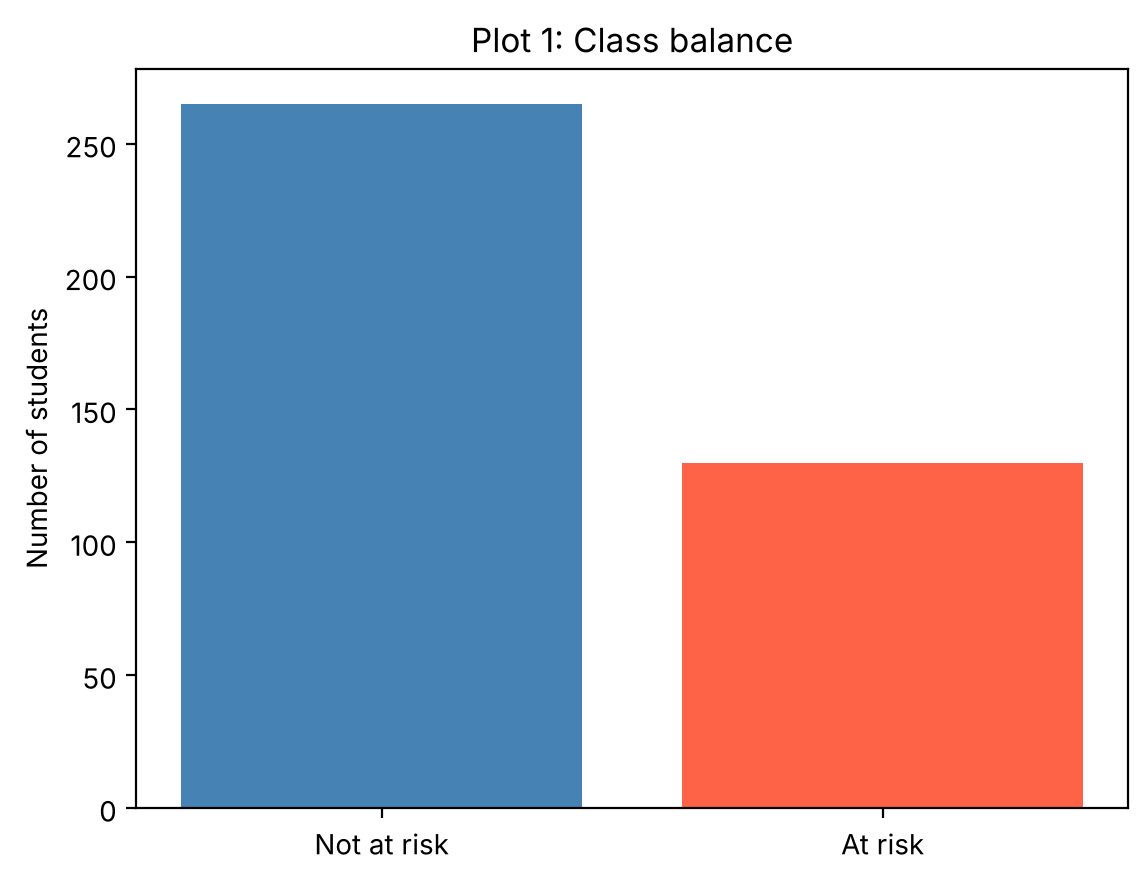

In [5]:
# Plot 1 - class balance
counts = df["at_risk"].value_counts().sort_index()
plt.bar(["Not at risk", "At risk"], counts.values, color=["steelblue", "tomato"])
plt.title("Plot 1: Class balance")
plt.ylabel("Number of students")
plt.show()

**Plot 1:** About one third of students (130 of 395) are at risk. A model that says "not at risk" for everybody would be 67% accurate and catch nobody, so accuracy alone is misleading. That is why we focus on recall and F1.

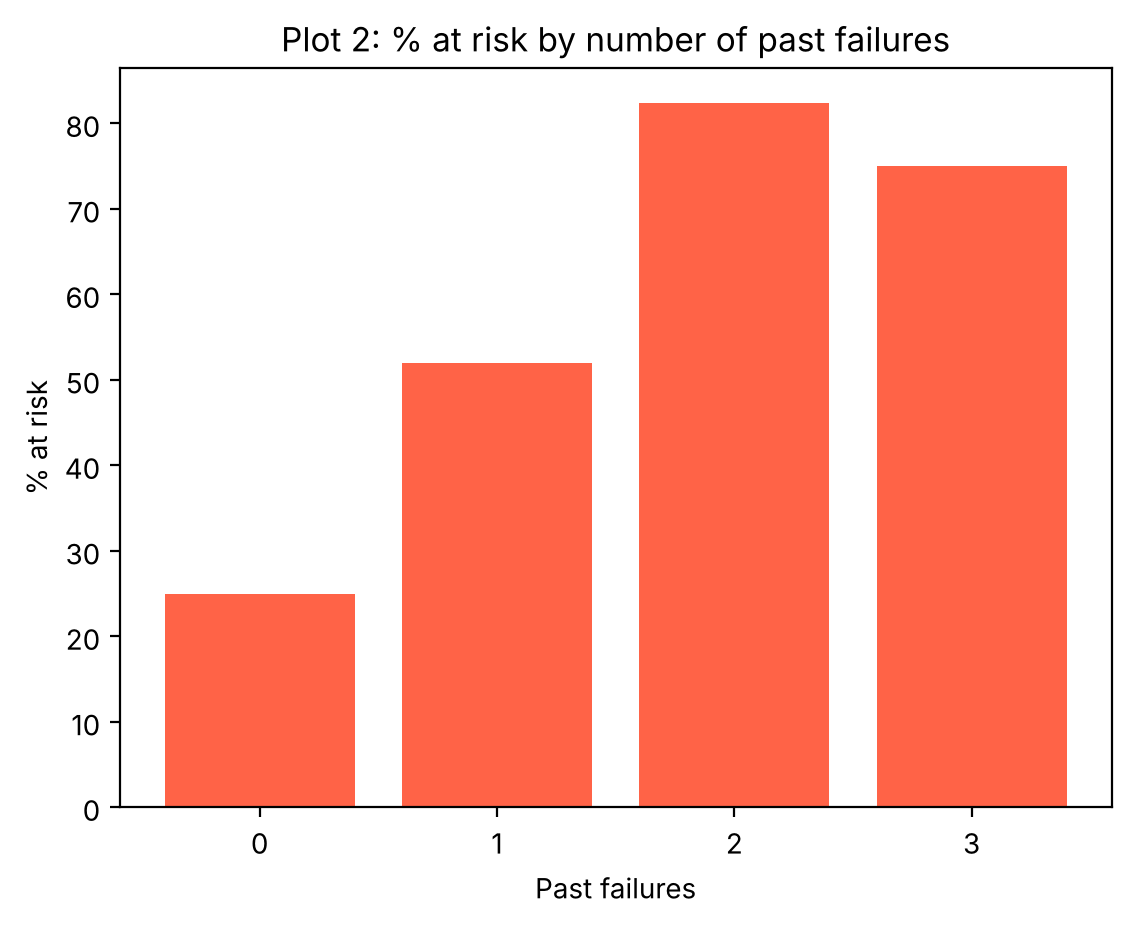

{0: 25.0, 1: 52.0, 2: 82.0, 3: 75.0} {0: 312, 1: 50, 2: 17, 3: 16}


In [6]:
# Plot 2 - past failures vs at-risk rate
rate = df.groupby("failures")["at_risk"].mean() * 100
plt.bar(rate.index.astype(str), rate.values, color="tomato")
plt.title("Plot 2: % at risk by number of past failures")
plt.xlabel("Past failures")
plt.ylabel("% at risk")
plt.show()
print(rate.round(0).to_dict(), df["failures"].value_counts().sort_index().to_dict())

**Plot 2:** Past failures are a strong warning sign. Only about 25% of students with no past failures are at risk, rising to about 52% with one failure and above 75% with two or more. The groups with 2 and 3 failures are small (17 and 16 students), so those exact percentages are not stable, but the direction is clear.

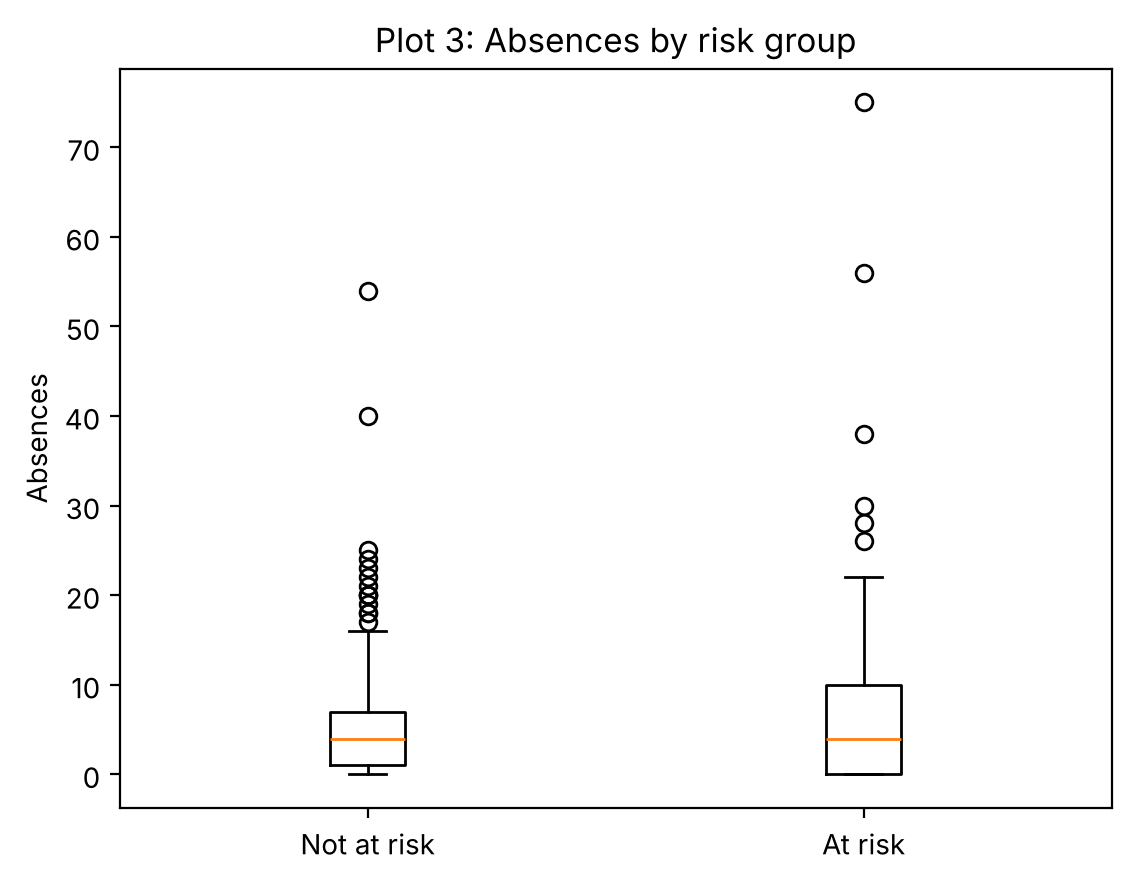

         count  mean    std  min  25%  50%   75%   max
at_risk                                               
0        265.0  5.19   6.41  0.0  1.0  4.0   7.0  54.0
1        130.0  6.76  10.48  0.0  0.0  4.0  10.0  75.0


In [7]:
# Plot 3 - absences for both groups
plt.boxplot([df.loc[df.at_risk == 0, "absences"], df.loc[df.at_risk == 1, "absences"]])
plt.xticks([1, 2], ["Not at risk", "At risk"])
plt.title("Plot 3: Absences by risk group")
plt.ylabel("Absences")
plt.show()
print(df.groupby("at_risk")["absences"].describe().round(2))

**Plot 3:** The two groups look similar (median 4 absences each). The reason is a data quirk: all 38 students with `G3 = 0` have `absences = 0`, which pulls the at-risk group down. Without them, at-risk students average about 9.6 absences vs about 5.2 for the others. So absences are useful, but the zero-grade students hide the effect.

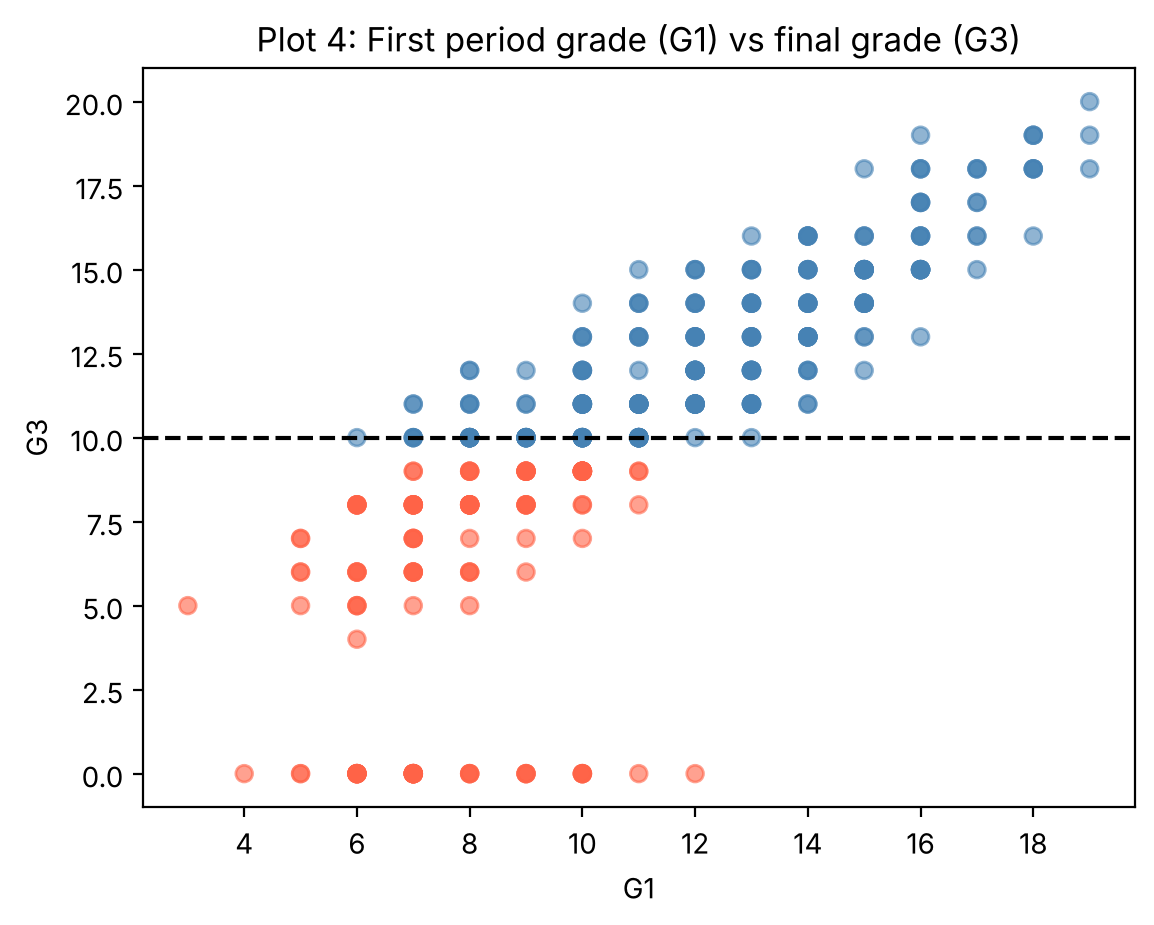

Correlation G1-G3: 0.8 | G2-G3: 0.9


In [8]:
# Plot 4 - G1 vs G3
colors = df["at_risk"].map({0: "steelblue", 1: "tomato"})
plt.scatter(df["G1"], df["G3"], c=colors, alpha=0.6)
plt.axhline(PASS_MARK, color="black", linestyle="--")
plt.title("Plot 4: First period grade (G1) vs final grade (G3)")
plt.xlabel("G1")
plt.ylabel("G3")
plt.show()
print("Correlation G1-G3:", round(df["G1"].corr(df["G3"]), 2), "| G2-G3:", round(df["G2"].corr(df["G3"]), 2))

**Plot 4:** There is a strong positive relationship between `G1` and `G3` (correlation about 0.80). Students with a low G1 fail very often, those with a high G1 almost never do. That is why `G1` is such a powerful feature. `G2` is even closer to `G3` (about 0.90), so we treat it with caution.

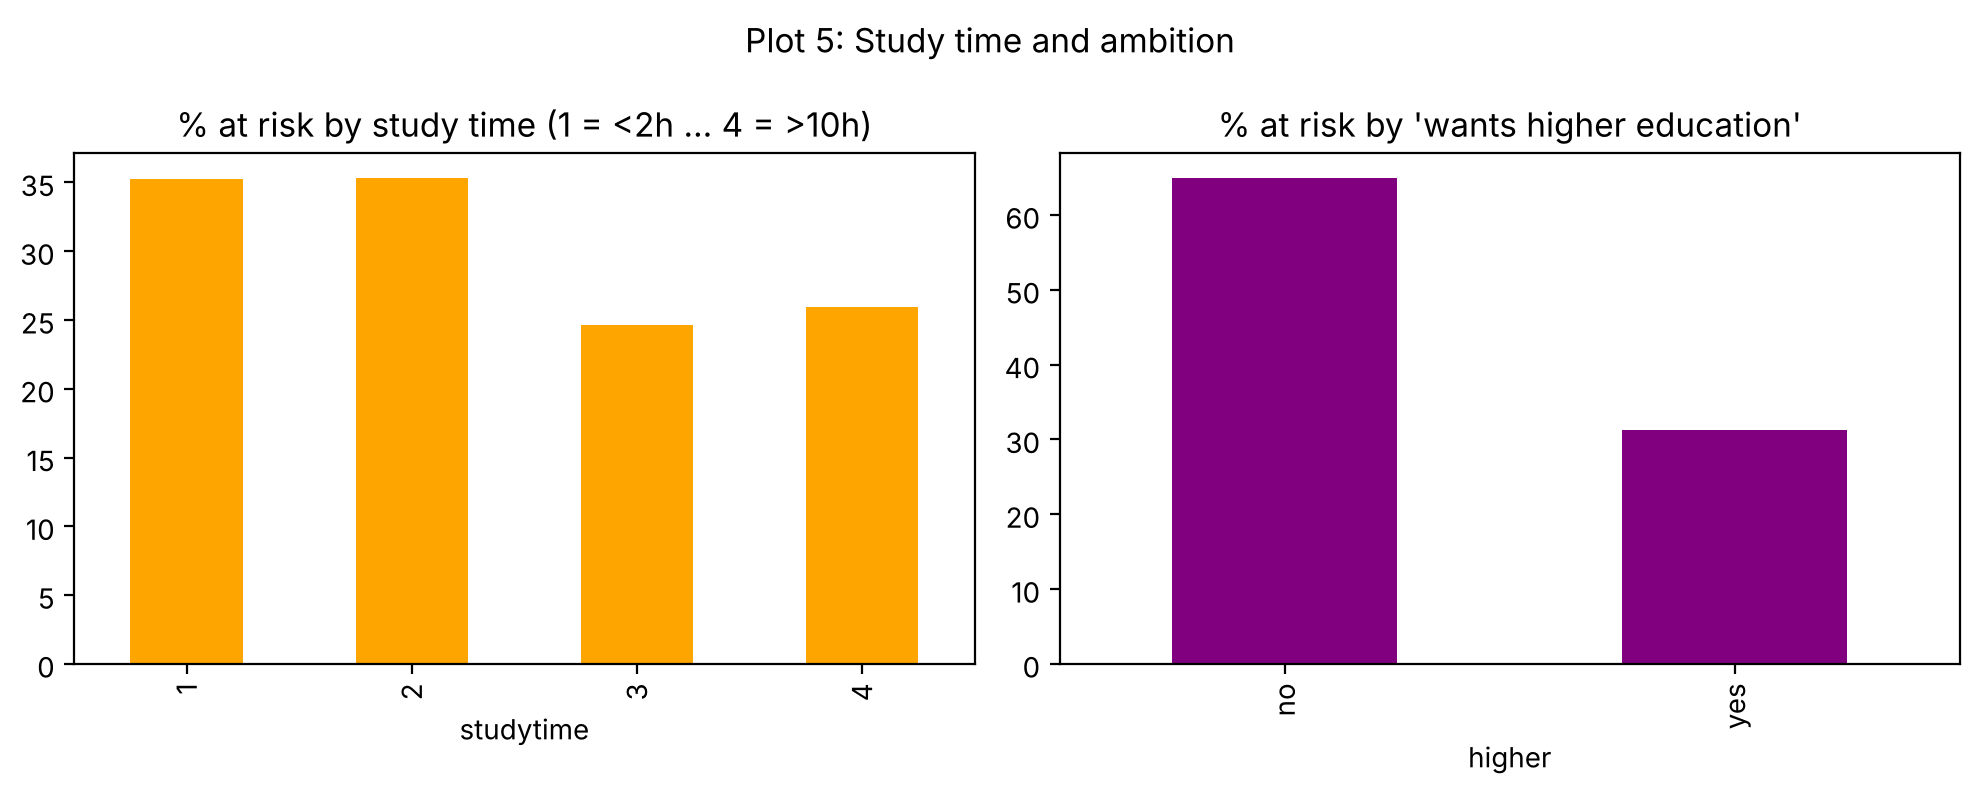

        mean  size
higher            
no      0.65    20
yes     0.31   375


In [9]:
# Plot 5 - study time and wanting higher education
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
(df.groupby("studytime")["at_risk"].mean() * 100).plot(kind="bar", ax=ax[0], color="orange")
ax[0].set_title("% at risk by study time (1 = <2h ... 4 = >10h)")
(df.groupby("higher")["at_risk"].mean() * 100).plot(kind="bar", ax=ax[1], color="purple")
ax[1].set_title("% at risk by 'wants higher education'")
plt.suptitle("Plot 5: Study time and ambition")
plt.tight_layout()
plt.show()
print(df.groupby("higher")["at_risk"].agg(["mean", "size"]).round(2))

**Plot 5:** Students who study less (levels 1-2) are at risk more often than those who study more (levels 3-4), but the effect is modest. The ambition effect is stronger: students who do *not* want higher education are at risk about 65% of the time vs about 31% for those who do. Only 20 students answered "no", and this shows motivation, not cause.

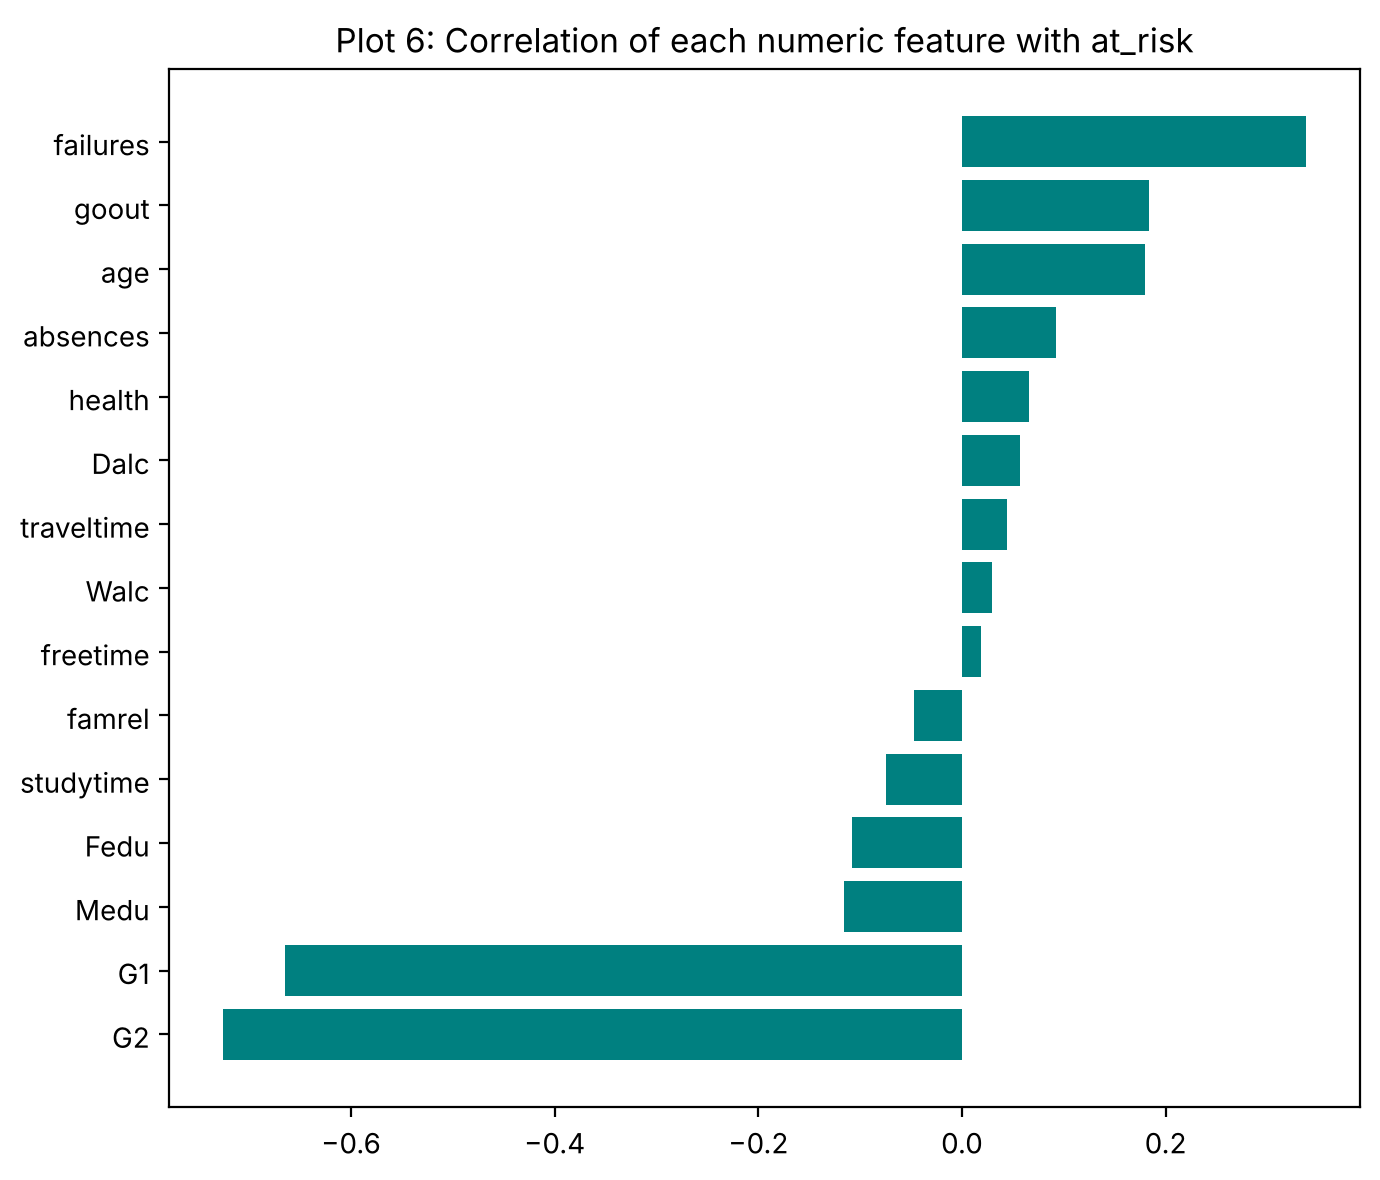

In [10]:
# Plot 6 - correlation of numeric columns with the target
corr = df.select_dtypes("number").drop(columns=["G3"]).corr()["at_risk"].drop("at_risk").sort_values()
plt.figure(figsize=(7, 6))
plt.barh(corr.index, corr.values, color="teal")
plt.title("Plot 6: Correlation of each numeric feature with at_risk")
plt.tight_layout()
plt.show()

**Plot 6:** `failures`, `goout` and `age` are the most positively related to risk, and parents' education (`Medu`, `Fedu`) is slightly negative. `G1` and `G2` are the strongest overall (negative: higher grades mean lower risk). Most lifestyle variables (free time, alcohol, health, travel time) have almost no relationship with risk on their own.

## 6. Feature Selection and Train/Test Split (Milestone 5)

We test three feature sets, because they match three moments when a teacher could use the tool:

| Feature set | When can it be used? | Contains |
|---|---|---|
| `early` | Before any grade exists | background, family, habits, absences, failures |
| `g1` | After the first-period results | the above + `G1` |
| `all` | After the second-period results | the above + `G1` + `G2` |

**Split:** 80% train / 20% test, stratified on the target, fixed seed. The scaler and encoder live inside a `Pipeline`, so they are fitted **only on training data** (no data leakage). The test set is never used to choose models or settings.

In [11]:
X = df.drop(columns=["G3", "at_risk"])      # G3 is removed - it IS the target
y = df["at_risk"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("At-risk share -> train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

# columns to drop for each feature set
DROP = {"all": [], "g1": ["G2"], "early": ["G1", "G2"]}

Train: (316, 32) | Test: (79, 32)
At-risk share -> train: 0.329 | test: 0.329


## 7. Baseline Model (Milestone 5)
**Baseline = Logistic Regression** with all features. It is simple, fast and easy to explain to a non-technical stakeholder.

The helper below builds a pipeline that scales number columns and one-hot encodes text columns, then runs the model.

Accuracy : 0.937
Precision: 0.957
Recall   : 0.846
F1       : 0.898


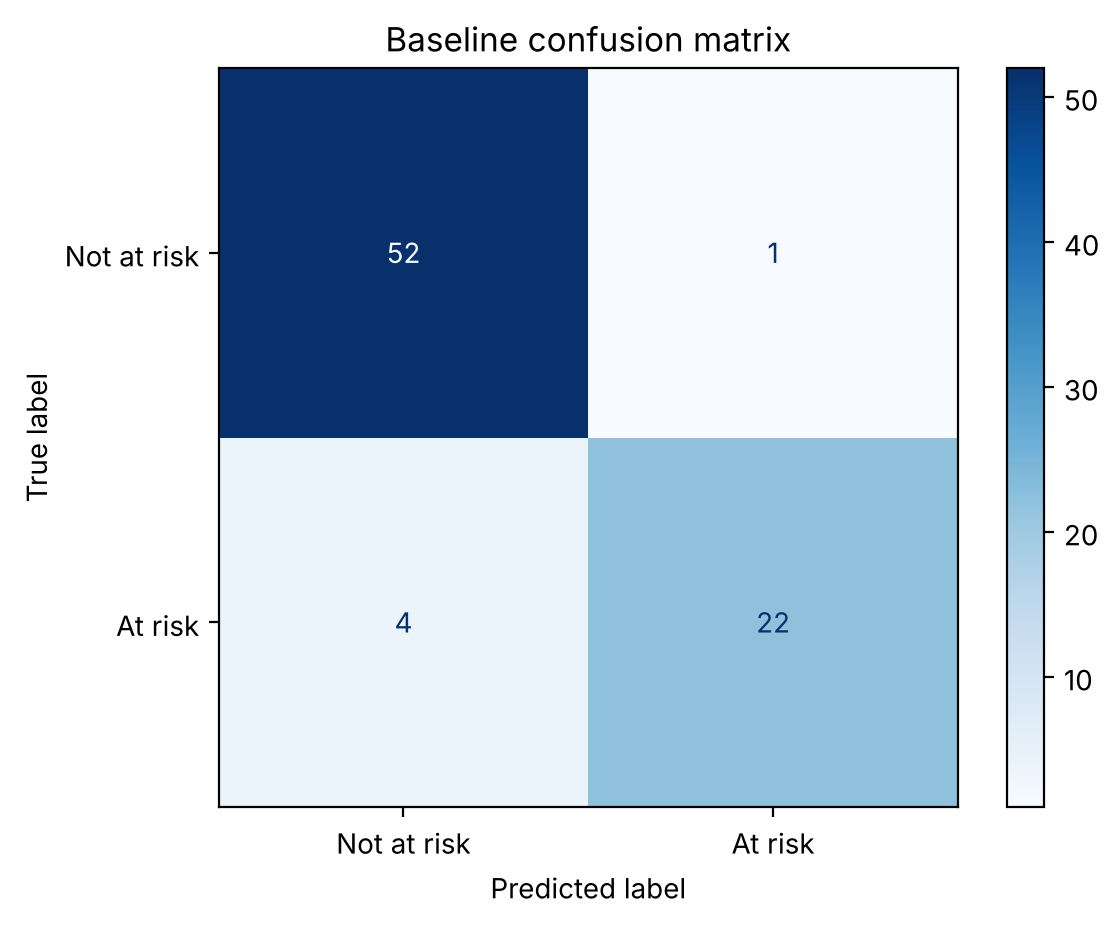

In [12]:
def make_model(model):
    prep = make_column_transformer(
        (StandardScaler(), make_column_selector(dtype_include="number")),
        (OneHotEncoder(handle_unknown="ignore", drop="if_binary"), make_column_selector(dtype_exclude="number")),
    )
    return make_pipeline(prep, model)

baseline = make_model(LogisticRegression(max_iter=1000))
baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall   :", round(recall_score(y_test, pred), 3))
print("F1       :", round(f1_score(y_test, pred), 3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Not at risk", "At risk"], cmap="Blues")
plt.title("Baseline confusion matrix")
plt.show()

**Baseline result:** This looks excellent, but the baseline uses `G2`, the grade just before the final one. So it is mostly "reading" the second-period grade, which is not a real early warning. The experiments below check how much performance is left without those grades.

## 8. Experiments and Model Improvement (Milestones 5-6)
We run **7 experiments**, changing one thing at a time.

| Exp | What changed |
|---|---|
| 1 | Baseline: Logistic Regression, all features (G1 + G2) |
| 2 | Logistic Regression, no grades (early warning) |
| 3 | Logistic Regression, G1 only |
| 4 | Random Forest, no grades |
| 5 | Random Forest, G1 only |
| 6 | Random Forest with `class_weight="balanced"`, G1 only |
| 7 | Random Forest tuned with GridSearchCV, G1 only |

`cv_f1` is the average F1 from 5-fold cross-validation on the **training data only**. We use it to compare models, because the test set has only 79 students (26 at risk), so one student changes recall by about 4 points.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = []

def run(name, model, features):
    cols = X_train.columns.drop(DROP[features])
    pipe = make_model(model)
    cv_f1 = cross_val_score(pipe, X_train[cols], y_train, cv=cv, scoring="f1").mean()
    pipe.fit(X_train[cols], y_train)
    pred = pipe.predict(X_test[cols])
    results.append({"exp": name,
                    "accuracy": accuracy_score(y_test, pred),
                    "precision": precision_score(y_test, pred),
                    "recall": recall_score(y_test, pred),
                    "f1": f1_score(y_test, pred),
                    "cv_f1": cv_f1})

lr = LogisticRegression(max_iter=1000)
rf = RandomForestClassifier(n_estimators=200, random_state=SEED)
rf_bal = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED)

run("Exp1 LogReg | all",         lr,     "all")
run("Exp2 LogReg | early",       lr,     "early")
run("Exp3 LogReg | G1",          lr,     "g1")
run("Exp4 RandForest | early",   rf,     "early")
run("Exp5 RandForest | G1",      rf,     "g1")
run("Exp6 RF balanced | G1",     rf_bal, "g1")

pd.DataFrame(results).set_index("exp").round(3)

,accuracy,precision,recall,f1,cv_f1
exp,,,,,
Exp1 LogReg | all,0.937,0.957,0.846,0.898,0.855
Exp2 LogReg | early,0.696,0.571,0.308,0.400,0.403
Exp3 LogReg | G1,0.848,0.792,0.731,0.760,0.715
Exp4 RandForest | early,0.709,0.636,0.269,0.378,0.366
Exp5 RandForest | G1,0.886,0.947,0.692,0.800,0.646
Exp6 RF balanced | G1,0.835,0.710,0.846,0.772,0.760


### Hyperparameter tuning (Exp 7)

Best params: {'randomforestclassifier__class_weight': 'balanced', 'randomforestclassifier__max_depth': 10, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 100}
Best CV F1 : 0.778


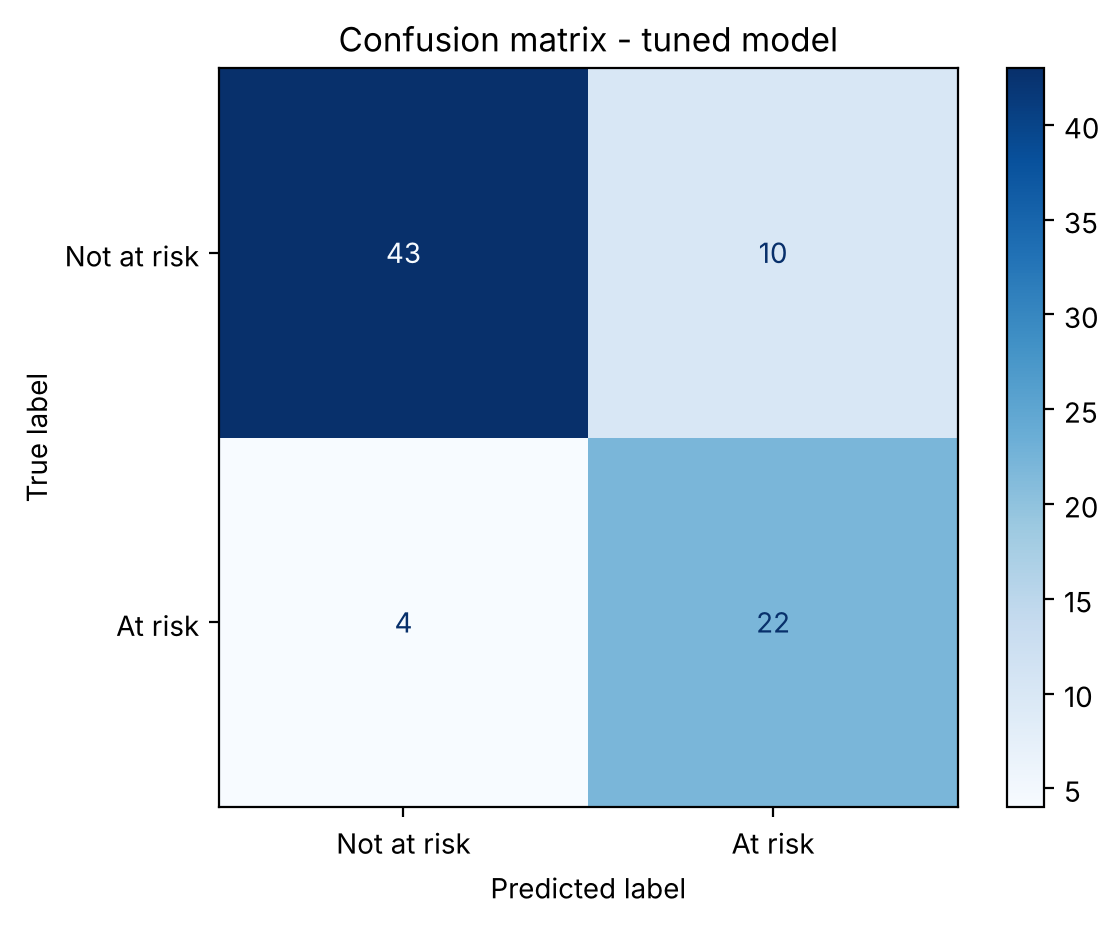

,accuracy,precision,recall,f1,cv_f1
exp,,,,,
Exp1 LogReg | all,0.937,0.957,0.846,0.898,0.855
Exp2 LogReg | early,0.696,0.571,0.308,0.400,0.403
Exp3 LogReg | G1,0.848,0.792,0.731,0.760,0.715
Exp4 RandForest | early,0.709,0.636,0.269,0.378,0.366
Exp5 RandForest | G1,0.886,0.947,0.692,0.800,0.646
Exp6 RF balanced | G1,0.835,0.710,0.846,0.772,0.760
Exp7 Tuned RF | G1,0.823,0.688,0.846,0.759,0.778


In [14]:
g1_cols = X_train.columns.drop(DROP["g1"])

param_grid = {
    "randomforestclassifier__n_estimators": [100, 300],
    "randomforestclassifier__max_depth": [None, 5, 10],
    "randomforestclassifier__min_samples_leaf": [1, 3, 5],
    "randomforestclassifier__class_weight": [None, "balanced"],
}
grid = GridSearchCV(make_model(RandomForestClassifier(random_state=SEED)),
                    param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train[g1_cols], y_train)
print("Best params:", grid.best_params_)
print("Best CV F1 :", round(grid.best_score_, 3))

final_model = grid.best_estimator_
pred = final_model.predict(X_test[g1_cols])
results.append({"exp": "Exp7 Tuned RF | G1",
                "accuracy": accuracy_score(y_test, pred),
                "precision": precision_score(y_test, pred),
                "recall": recall_score(y_test, pred),
                "f1": f1_score(y_test, pred),
                "cv_f1": grid.best_score_})

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Not at risk", "At risk"], cmap="Blues")
plt.title("Confusion matrix - tuned model")
plt.show()

table = pd.DataFrame(results).set_index("exp").round(3)
table

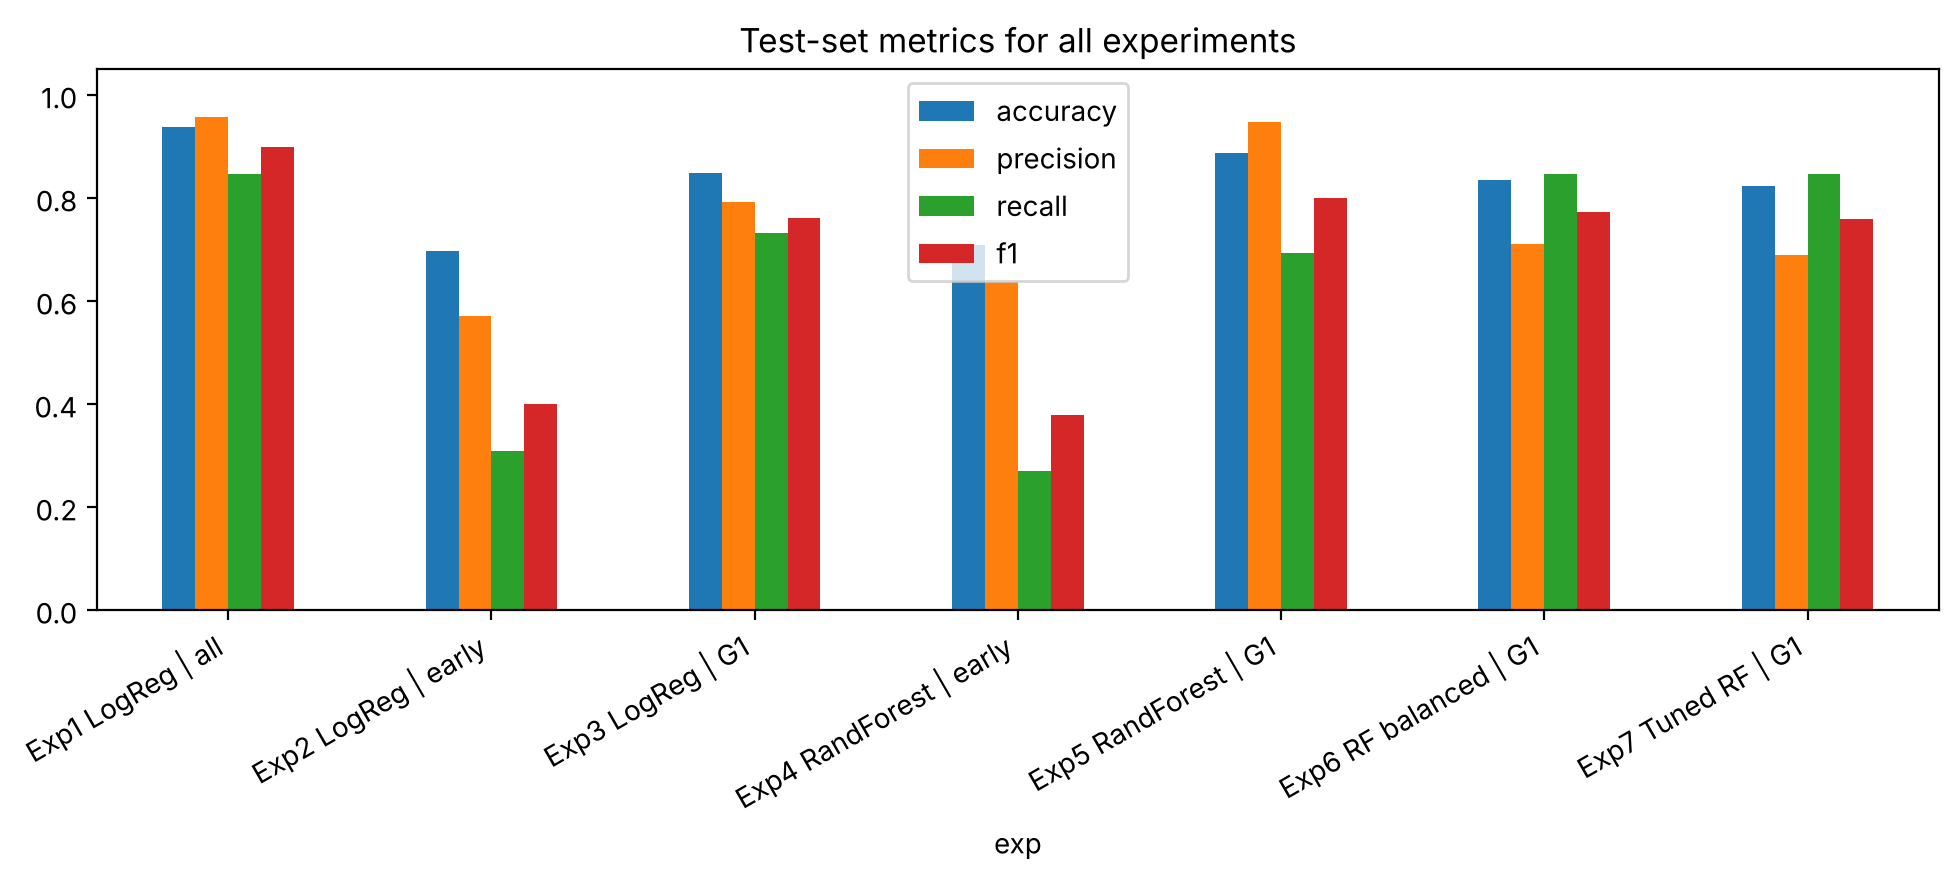

In [15]:
table[["accuracy", "precision", "recall", "f1"]].plot(kind="bar", figsize=(10, 4.5))
plt.title("Test-set metrics for all experiments")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Experiment interpretation
- **Exp 1 (G1 + G2) is the best on paper (F1 0.90), but it is not a real early warning.** `G2` is the grade right before the final exam, so by then the teacher already sees the problem. We keep it only as a reference "upper limit".
- **Exp 2 and 4 (no grades) are weak:** recall is only 0.31 (LogReg) and 0.27 (Random Forest). Background and lifestyle alone cannot find at-risk students. This is an important honest result.
- **Adding only `G1` changes everything** (Exp 3 and 5): F1 jumps from about 0.40 to 0.76-0.80. One early grade carries most of the signal.
- **Class balancing helps recall:** Random Forest alone (Exp 5) has high precision (0.95) but misses many at-risk students (recall 0.69). With `class_weight="balanced"` (Exp 6) recall rises to 0.85 and precision falls to 0.71. That trade-off is what we want here.
- **Tuning (Exp 7)** gives the best cross-validated F1 (0.778), so it is our **final model**. We chose it by cross-validation on the training data, **not** by looking at the best test score.
- **Small test set:** Exp 5, 6 and 7 differ by only a few students on the test set, so we cannot claim one is clearly better from test results alone.

**Success criteria check (Exp 7, test set):** recall 0.846 meets the target (≥ 0.80) and precision 0.688 meets the target (≥ 0.65). Both are met, but with only 26 at-risk students in the test set the margins are small.

### Which features drive the final model?

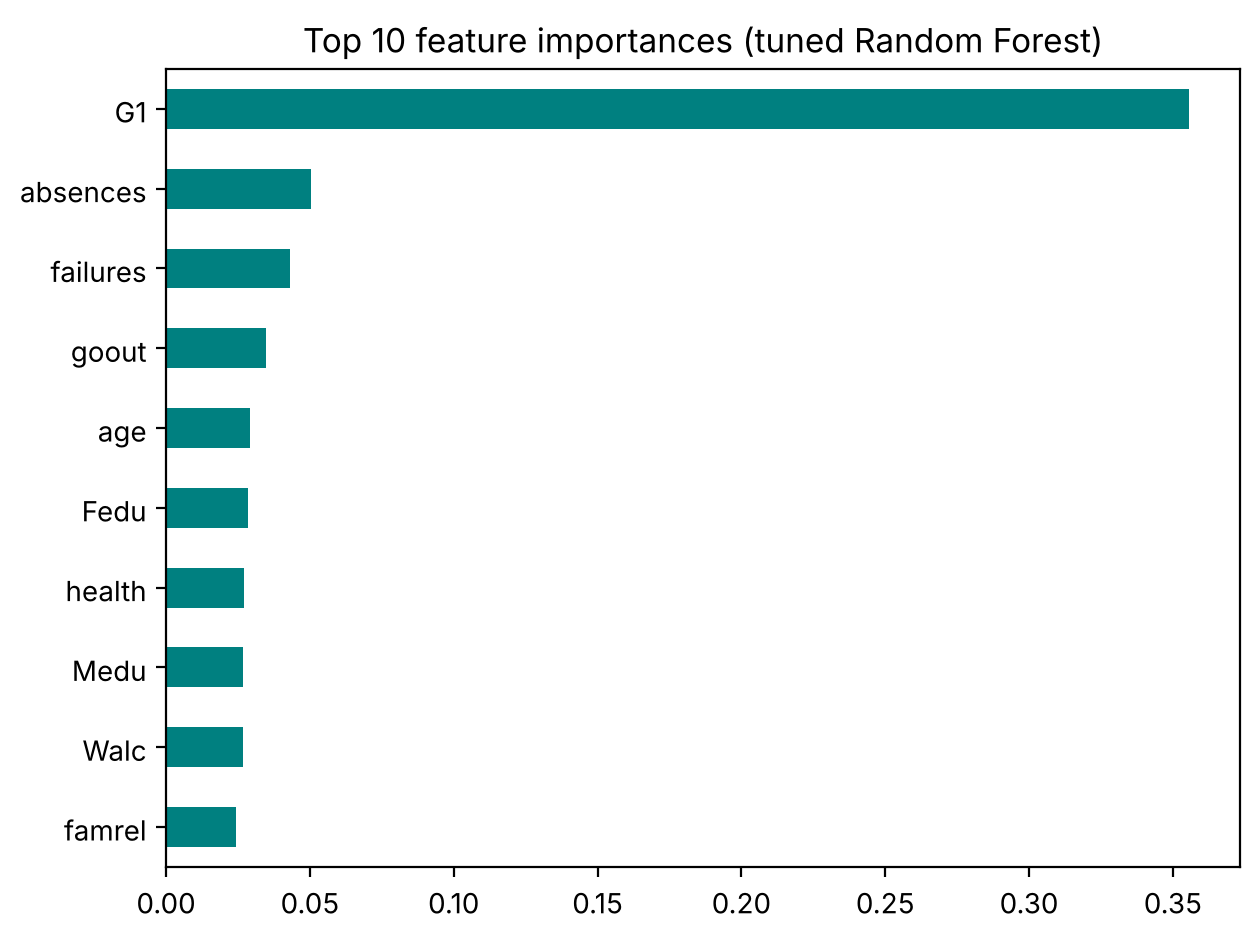

G1          0.356
absences    0.051
failures    0.043
goout       0.035
age         0.029
Fedu        0.029
health      0.027
Medu        0.027
Walc        0.027
famrel      0.024
dtype: float64

In [16]:
names = final_model[0].get_feature_names_out()
importance = pd.Series(final_model[-1].feature_importances_, index=names).sort_values(ascending=False)
importance.index = [n.split("__")[1] for n in importance.index]
importance.head(10)[::-1].plot(kind="barh", color="teal")
plt.title("Top 10 feature importances (tuned Random Forest)")
plt.tight_layout()
plt.show()
importance.head(10).round(3)

`G1` is by far the most important feature (about 0.36). Everything else is small: absences, past failures, going out, age and parents' education. This matches the EDA. The tool is mainly "first-term grade plus a few risk factors", which is good for explainability.

## 9. Testing and Reliability (Milestone 7)

### 9.1 Errors we found while building and how we fixed them

| # | Problem found | Fix |
|---|---|---|
| 1 | The CSV uses `;` as separator, so reading it normally gives one single column | Use `sep=";"` |
| 2 | One-hot encoding crashes when a new, unseen category appears at prediction time | Use `handle_unknown="ignore"` in the pipeline |
| 3 | Our first results with `G2` looked "too good", so we realised `G2` is almost the final grade | Made three feature sets (early / G1 / all) and chose the final model without `G2` |
| 4 | Newer pandas stores text as `str` instead of `object`, so checking `dtype == "object"` failed | Select columns with `make_column_selector(dtype_include="number")` |

### 9.2 Prediction function with input checks
This is what a teacher-facing tool would call for one student. It checks the input first.

In [17]:
def predict_student(record):
    """Predict risk for ONE student (a dict). Returns (label, probability)."""
    if not isinstance(record, dict):
        raise TypeError("record must be a dict")
    missing = [c for c in g1_cols if c not in record]
    if missing:
        raise KeyError(f"missing fields: {missing}")
    if any(record[c] is None or record[c] != record[c] for c in g1_cols):   # None or NaN
        raise ValueError("some fields are empty")
    if not 15 <= record["age"] <= 22:
        raise ValueError("age must be between 15 and 22")
    if record["absences"] < 0:
        raise ValueError("absences cannot be negative")
    if not 0 <= record["G1"] <= 20:
        raise ValueError("G1 must be between 0 and 20")

    prob = final_model.predict_proba(pd.DataFrame([record])[g1_cols])[0, 1]
    return ("AT RISK" if prob >= 0.5 else "not at risk"), round(float(prob), 3)


good = X_test[g1_cols].iloc[0].to_dict()
print("Normal record ->", predict_student(good))

Normal record -> ('AT RISK', 0.8)


### 9.3 Edge cases

In [18]:
def test(name, record):
    try:
        print(f"[NOT HANDLED] {name} -> {predict_student(record)}")
    except Exception as e:
        print(f"[HANDLED]     {name} -> {type(e).__name__}: {e}")

no_absences = {k: v for k, v in good.items() if k != "absences"}

test("1. missing field (absences)", no_absences)
test("2. age = 150",              {**good, "age": 150})
test("3. negative absences",      {**good, "absences": -5})
test("4. NaN grade",              {**good, "G1": float("nan")})
test("5. G1 = 99",                {**good, "G1": 99})
test("6. record is a list",       [1, 2, 3])

[HANDLED]     1. missing field (absences) -> KeyError: "missing fields: ['absences']"
[HANDLED]     2. age = 150 -> ValueError: age must be between 15 and 22
[HANDLED]     3. negative absences -> ValueError: absences cannot be negative
[HANDLED]     4. NaN grade -> ValueError: some fields are empty
[HANDLED]     5. G1 = 99 -> ValueError: G1 must be between 0 and 20
[HANDLED]     6. record is a list -> TypeError: record must be a dict


All edge cases are rejected with a clear error instead of giving a wrong prediction.

### 9.4 Extra check on different data (Portuguese-class file)

In [19]:
por["at_risk"] = (por["G3"] < PASS_MARK).astype(int)
pred_por = final_model.predict(por[g1_cols])

print("Accuracy :", round(accuracy_score(por["at_risk"], pred_por), 3))
print("Recall   :", round(recall_score(por["at_risk"], pred_por), 3))
print("Precision:", round(precision_score(por["at_risk"], pred_por), 3))

Accuracy : 0.824
Recall   : 0.89
Precision: 0.464


The model catches most at-risk students in the Portuguese file (recall 0.89), but precision is low (0.46). That class has a much lower failure rate (about 15%), so the same model raises many false alarms. The model is **tuned to the Maths class and should not be moved to another subject or school without re-training**. Also, many of these students are the same people as in the Maths file, so this is only a rough check, not a fully independent test.

## 10. Stakeholder Recommendation and Limitations (Milestone 8)

**Recommendation for the school**
- Use the model after the **first-term results** as a *screening list* of students a teacher should talk to. In our test it found about 85% of the students who really failed (22 out of 26), but about 3 in 10 of its alerts were false alarms.
- Treat every alert as "please look at this student", never as a verdict.
- Do **not** rely on background information alone at the start of the course. Without any grade the model found less than a third of at-risk students.

**What the tool must NOT be used for**
- Deciding grades, punishments, streaming or removing students from a course.
- Judging students by family background, parents' jobs, alcohol use or relationship status. These sensitive attributes are in the data only because the original study collected them. A real deployment should consider removing them and test fairness across groups (sex, school, address type).
- Using it in another subject, school or country without re-training.

**Limitations**
- Small dataset (395 students) and small test set (79 students, 26 at risk), so results are uncertain. Differences of a few students are not meaningful.
- Only two Portuguese schools, data from 2005-2006. It may not represent other places or today's students.
- 38 students with `G3 = 0` may be dropouts, and they also have 0 absences, which can confuse the model.
- "Fail" uses a fixed cutoff of 10; a real school's pass mark may differ.
- We did not test fairness between groups or compute confidence intervals.

**Validation needed before deployment**
- Re-train and test on the school's own recent students.
- Check fairness across groups and review which features are acceptable.
- Run a pilot where teachers review the alerts, and measure whether extra support improves results.
- Keep student data private and get permission to use it.

---
## 11. References
1. Cortez, P. and Silva, A. (2008). Using Data Mining to Predict Secondary School Student Performance. FUBUTEC 2008, EUROSIS, pp. 5-12.
2. UCI Machine Learning Repository. Student Performance dataset. https://archive.ics.uci.edu/dataset/320/student+performance (accessed 27 Nov 2026).
3. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. JMLR 12, 2825-2830.
4. McKinney, W. (2010). Data Structures for Statistical Computing in Python. Proc. 9th Python in Science Conference.
5. Hunter, J. D. (2007). Matplotlib: A 2D Graphics Environment. Computing in Science & Engineering 9(3), 90-95.
6. Data files fetched from a public GitHub mirror of the UCI files: https://github.com/arunk13/MSDA-Assignments (folder IS607Fall2015/Assignment3).